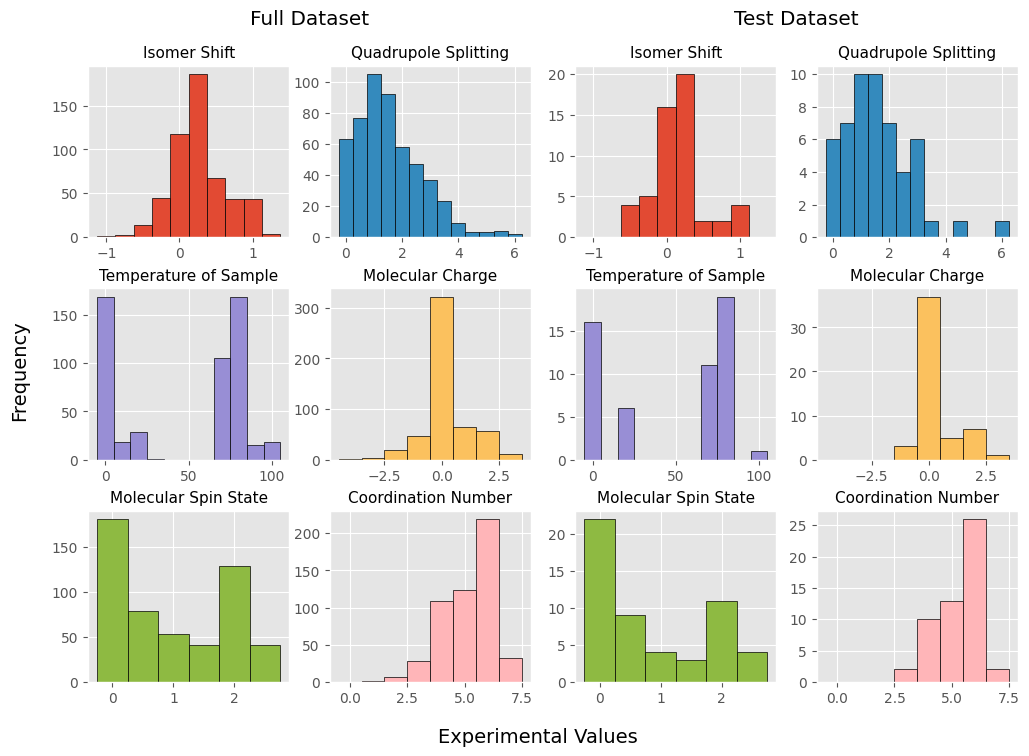

In [40]:
from rdkit.Chem import AllChem as chem
from rdkit import Chem as c
import os.path as osp
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec

data_folder = 'dataset/mossbauer/raw'
smiles_csv = pd.read_csv(osp.join(data_folder, 'annotations.tsv'),sep='\t')

file_list = list(smiles_csv.iloc[:,0])
mol_list = []

for file in file_list:
    file_path = None
    if(osp.exists((file_path := osp.join(data_folder, file[:-4], 'xtbtopo.mol')))):
        pass
    else:
        file_path = osp.join(data_folder, file[:-4], 'xtbopt.mol')

    mol = chem.MolFromMolFile(file_path, sanitize=False, removeHs=False)
    # Regenerate computed properties like implicit valence and ring information
    mol.UpdatePropertyCache(strict=False)

    # Apply several sanitization rules
    chem.SanitizeMol(mol,c.SanitizeFlags.SANITIZE_FINDRADICALS| \
                         c.SanitizeFlags.SANITIZE_SETAROMATICITY| \
                         c.SanitizeFlags.SANITIZE_SETCONJUGATION| \
                         c.SanitizeFlags.SANITIZE_SETHYBRIDIZATION| \
                         c.SanitizeFlags.SANITIZE_SYMMRINGS,catchErrors=True)
    mol_list.append(mol)

IS = np.asarray(smiles_csv.iloc[:, 1])
QS = np.asarray(smiles_csv.iloc[:, 2]).astype(np.float64)
TEMP = np.asarray(smiles_csv.loc[:, 'TEMP'])
charges = np.asarray(smiles_csv.loc[:, 'CHARGE'])
spin = np.asarray(smiles_csv.loc[:, 'SPIN'])
coordination = np.asarray([])

for m in mol_list:
    for a in m.GetAtoms():
        if a.GetAtomicNum() == 26:
            coordination = np.append(coordination, a.GetDegree())

indices = [0,2,10,11,15,22,30,33,55,63,70,73,75,78,79,93,101,124,131,132,137,140,
           148,153,158,177,209,210,228,247,250,253,277,287,289,291,310,318,325,360,
           375,397,406,418,426,437,449,482,486,510,512,519,522]

IS_test = np.asarray(smiles_csv.iloc[indices, 1])
QS_test = np.asarray(smiles_csv.iloc[indices, 2]).astype(np.float64)
TEMP_test = np.asarray(smiles_csv.loc[indices, 'TEMP'])
charges_test = np.asarray(smiles_csv.loc[indices, 'CHARGE'])
spin_test = np.asarray(smiles_csv.loc[indices, 'SPIN'])
coordination_test = coordination[indices]

wspace_outer = 0.1
wspace_inner = 0.2
hspace_inner = 0.3
subplot_title_size = 11
axis_font_size = 14

plt.style.use('ggplot')
fig = plt.figure(figsize=(12,8))
outer = gridspec.GridSpec(1, 2, wspace=wspace_outer)
inner1 = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=outer[0],
                                          wspace=wspace_inner, hspace=hspace_inner)
#fig, ax = plt.subplots(3, 2)

ax = plt.Subplot(fig, inner1[0])
ax.hist(IS, 
              bins=[-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5], 
              edgecolor='black',
              color='C0',
              align='left')
ax.set_title('Isomer Shift', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner1[1])
ax.hist(QS, 
              bins=[0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5], 
              edgecolor='black',
              color='C1',
              align='left')
ax.set_title('Quadrupole Splitting', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner1[2])
ax.hist(TEMP,
              bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110], 
              edgecolor='black',
              color='C2',
              align='left')
ax.set_title('Temperature of Sample', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner1[3])
ax.hist(charges,
              bins=[-4, -3, -2, -1, 0, 1, 2, 3, 4], 
              edgecolor='black',
              color='C4',
              align='left')
ax.set_title('Molecular Charge', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner1[4])
ax.hist(spin,
              bins=[0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0], 
              edgecolor='black',
              color='C5',
              align='left')
ax.set_title('Molecular Spin State', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner1[5])
ax.hist(coordination,
              bins=[0, 1, 2, 3, 4, 5, 6, 7, 8], 
              edgecolor='black',
              color='C6',
              align='left')
ax.set_title('Coordination Number', fontsize=subplot_title_size)
fig.add_subplot(ax)

#plt.subplots_adjust(wspace=0.2, hspace=0.5)

inner2 = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=outer[1],
                                          wspace=wspace_inner, hspace=hspace_inner)

ax = plt.Subplot(fig, inner2[0])
ax.hist(IS_test, 
              bins=[-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5], 
              edgecolor='black',
              color='C0',
              align='left')
ax.set_title('Isomer Shift', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner2[1])
ax.hist(QS_test, 
              bins=[0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5], 
              edgecolor='black',
              color='C1',
              align='left')
ax.set_title('Quadrupole Splitting', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner2[2])
ax.hist(TEMP_test,
              bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110], 
              edgecolor='black',
              color='C2',
              align='left')
ax.set_title('Temperature of Sample', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner2[3])
ax.hist(charges_test,
              bins=[-4, -3, -2, -1, 0, 1, 2, 3, 4], 
              edgecolor='black',
              color='C4',
              align='left')
ax.set_title('Molecular Charge', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner2[4])
ax.hist(spin_test,
              bins=[0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0], 
              edgecolor='black',
              color='C5',
              align='left')
ax.set_title('Molecular Spin State', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax = plt.Subplot(fig, inner2[5])
ax.hist(coordination_test,
              bins=[0, 1, 2, 3, 4, 5, 6, 7, 8], 
              edgecolor='black',
              color='C6',
              align='left')
ax.set_title('Coordination Number', fontsize=subplot_title_size)
fig.add_subplot(ax)

ax_left = fig.add_subplot(inner1[:])
ax_left.axis('off')
ax_left.set_title('Full Dataset',pad=30)

ax_right = fig.add_subplot(inner2[:])
ax_right.axis('off')
ax_right.set_title('Test Dataset',pad=30)

fig.supylabel('Frequency', fontsize=axis_font_size, x = 0.06)
fig.supxlabel('Experimental Values', fontsize=axis_font_size, y = 0.03)
plt.savefig('figures/histograms.svg', bbox_inches='tight')

LOW: MAE = 0.09315094339622644, MSE = 0.01686401886792453, R2 = 0.8678100055645281
LOW: MAE = 0.5315849056603774, MSE = 0.5450030943396226, R2 = 0.6217027474919574


<Figure size 500x500 with 0 Axes>

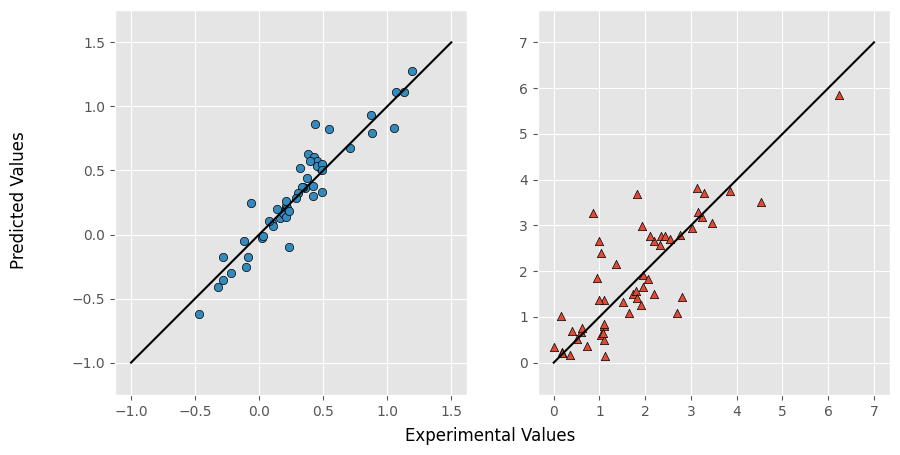

In [14]:
import os.path as osp
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

dft_low_csv = pd.read_csv('dft_gfn1-xtb_comparison.tsv',sep='\t')

out_low_is = dft_low_csv['DFT IS'].values
actual_low_is = dft_low_csv['IS'].values

mae_low = abs(actual_low_is - out_low_is).sum() / actual_low_is.shape[0]
mse_low = ((actual_low_is - out_low_is)**2).sum() / actual_low_is.shape[0]
r2_low = r2_score(actual_low_is, out_low_is)

print(f"LOW: MAE = {mae_low}, MSE = {mse_low}, R2 = {r2_low}")

plt.style.use('ggplot')
plt.figure(figsize=(5,5))
fig, ax = plt.subplots(1, 2, figsize=(10,5))

ax[0].scatter(actual_low_is, out_low_is, c='C1', edgecolors='k', marker='o', s=36, label='IS')
ax[0].plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
#plt.xlabel('Experimental Values', fontsize=15)
#plt.ylabel('Predicted Values', fontsize=15)
ax[0].axis('equal')
#ax[0].legend()
#plt.subplots_adjust(left=0.25)
#ax[0].savefig('figures/IS_predictions_DFT_comparison.svg', bbox_inches='tight')
#plt.show()

out_low_qs = dft_low_csv['DFT QS'].values
actual_low_qs = dft_low_csv['QS'].values

mae_low = abs(actual_low_qs - out_low_qs).sum() / actual_low_qs.shape[0]
mse_low = ((actual_low_qs - out_low_qs)**2).sum() / actual_low_qs.shape[0]
r2_low = r2_score(actual_low_qs, out_low_qs)

print(f"LOW: MAE = {mae_low}, MSE = {mse_low}, R2 = {r2_low}")

ax[1].scatter(actual_low_qs, out_low_qs, c='C0', edgecolors='k', marker='^', s=36, label='QS')
ax[1].plot([0.0, 7.0], [0.0, 7.0], 'k-')
#plt.xlabel('Experimental Values', fontsize=15)
#plt.ylabel('Predicted Values', fontsize=15)
ax[1].axis('equal')
#ax[1].legend()
#plt.subplots_adjust(left=0.25)

fig.supylabel('Predicted Values')
fig.supxlabel('Experimental Values')
#fig.legend()
plt.savefig('figures/IS_QS_predictions_DFT_comparison.svg', bbox_inches='tight')
plt.show()